## Clasificación de MRI cerebral con CNN
## Miniproyecto – Técnicas de Deep Learning

Objetivo: clasificar cortes 2D de MRI cerebral en 4 clases: glioma, meningioma, pituitary y healthy (sano).

Se comparan dos modelos:
- SimpleCNN: CNN pequeña entrenada desde cero.
- ResNet18-FT: ResNet18 preentrenada en ImageNet y ajustada.

Cada modelo se entrena con 3 semillas y se reporta media ± desviación estándar en prueba.

> Se ejecuta en local. Se recomienda una GPU NVIDIA; en CPU el entrenamiento puede tardar varias horas.

### 1. Configuración y datos
Si existe la carpeta local `archive/` (junto al notebook, con las subcarpetas `glioma`, `healthy`, `meningioma` y `pituitary`), se usa esa. Si no, como ocurre en Colab, se descarga el *Brain Tumor MRI Dataset* de Kaggle con `kagglehub`.

In [10]:
import os, copy, random, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models
import torchvision.transforms as T

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')   # GPU de Apple Silicon
else:
    device = torch.device('cpu')
print('Dispositivo:', device)

Dispositivo: mps


In [11]:
# Se usan los datos locales si existen; si no (p. ej. en Colab), se descargan de Kaggle
DATA_DIR = './archive'
if not os.path.isdir(DATA_DIR):
    import kagglehub
    DATA_DIR = kagglehub.dataset_download('masoudnickparvar/brain-tumor-mri-dataset')
print('Datos en:', os.path.abspath(DATA_DIR))

FIG_DIR = './resultados'
os.makedirs(FIG_DIR, exist_ok=True)


def fijar_semilla(s):
    """Hace reproducibles los experimentos."""
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)

Datos en: /Users/alejandrosanabria/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2


In [12]:
CLASES = ['glioma', 'meningioma', 'pituitary', 'healthy']
ALIAS = {'notumor': 'healthy'}   # en la versión de Kaggle la clase sana se llama 'notumor'

# Una fila por imagen: ruta y clase (la clase es el nombre de la carpeta)
filas = []
for carpeta, _, archivos in os.walk(DATA_DIR):
    clase = os.path.basename(carpeta).lower()
    clase = ALIAS.get(clase, clase)
    if clase in CLASES and '__MACOSX' not in carpeta:
        filas += [{'path': os.path.join(carpeta, f), 'label': clase}
                  for f in sorted(archivos) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
df = pd.DataFrame(filas)
print('Imágenes encontradas:', len(df))

Imágenes encontradas: 7200


### 2. Exploración

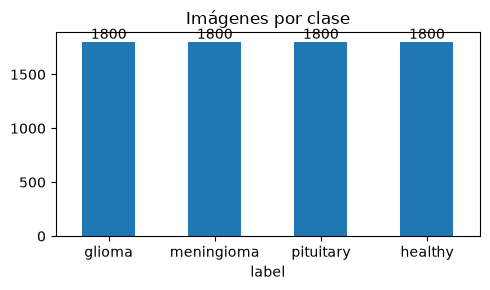

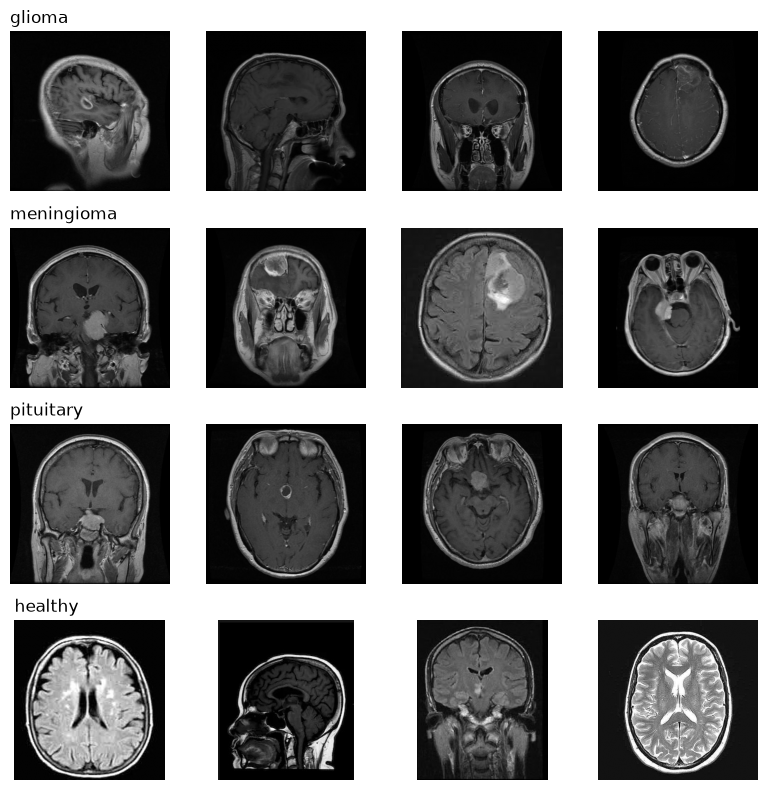

In [13]:
conteo = df['label'].value_counts().reindex(CLASES)
ax = conteo.plot.bar(rot=0, figsize=(5, 3), title='Imágenes por clase')
ax.bar_label(ax.containers[0])
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/distribucion_clases.png', dpi=300)
plt.show()

# 4 ejemplos por clase
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for i, c in enumerate(CLASES):
    for j, p in enumerate(df[df['label'] == c].sample(4, random_state=0)['path']):
        axes[i, j].imshow(Image.open(p).convert('L'), cmap='gray')
        axes[i, j].axis('off')
    axes[i, 0].set_title(c, loc='left')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/ejemplos_clases.png', dpi=300)
plt.show()

### 3. Limpieza y división
- Duplicados: el dataset tiene imágenes repetidas. Si una copia queda en train y otra en test, la exactitud sale inflada. Se detectan con el hash MD5: se deja una copia por grupo y se eliminan los grupos con etiquetas distintas.
- División: estratificada 70 % train / 15 % validación / 15 % prueba.

In [14]:
df['md5'] = [hashlib.md5(Path(p).read_bytes()).hexdigest() for p in df['path']]

conflicto = df.groupby('md5')['label'].transform('nunique') > 1   # misma imagen, distinta etiqueta
df_limpio = df[~conflicto].drop_duplicates('md5').reset_index(drop=True)
print(f'Originales: {len(df)} | en conflicto: {conflicto.sum()} | finales: {len(df_limpio)}')

df_train, df_temp = train_test_split(df_limpio, test_size=0.3, stratify=df_limpio['label'], random_state=42)
df_val, df_test = train_test_split(df_temp, test_size=0.5, stratify=df_temp['label'], random_state=42)

pd.DataFrame({'train': df_train['label'].value_counts(),
              'val': df_val['label'].value_counts(),
              'test': df_test['label'].value_counts()}).reindex(CLASES)

Originales: 7200 | en conflicto: 0 | finales: 7013


,train,val,test
label,,,
glioma,1250,268,268
meningioma,1249,267,268
pituitary,1233,265,264
healthy,1177,252,252


### 4. Preprocesamiento y aumento de datos
- Cada imagen se lee una sola vez, en gris y a 224×224, y se guarda en memoria.
- Se replica a 3 canales y se normaliza con la media/desviación de ImageNet (lo que espera ResNet18).
- Aumento (solo train): volteo horizontal, rotación ±10°, traslación 5 %, escala 0.95–1.05 y brillo/contraste ±20 %.

In [15]:
IMG_SIZE = 224
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

CACHE = {p: Image.open(p).convert('L').resize((IMG_SIZE, IMG_SIZE)) for p in df_limpio['path']}

transform_train = T.Compose([
    T.RandomHorizontalFlip(),
    T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    T.ColorJitter(brightness=0.2, contrast=0.2),
    T.Grayscale(3), T.ToTensor(), T.Normalize(MEAN, STD),
])
transform_eval = T.Compose([T.Grayscale(3), T.ToTensor(), T.Normalize(MEAN, STD)])


class MRIDataset(Dataset):
    """Devuelve (imagen transformada, índice de la clase)."""
    def __init__(self, tabla, transform):
        self.paths = list(tabla['path'])
        self.labels = [CLASES.index(l) for l in tabla['label']]
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        return self.transform(CACHE[self.paths[i]]), self.labels[i]


ds_train = MRIDataset(df_train, transform_train)
ds_val = MRIDataset(df_val, transform_eval)
ds_test = MRIDataset(df_test, transform_eval)
loader_val = DataLoader(ds_val, batch_size=64)
loader_test = DataLoader(ds_test, batch_size=64)

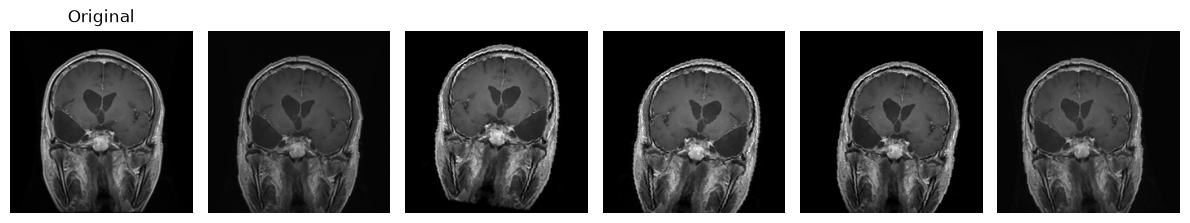

In [16]:
def desnormalizar(x):
    """Tensor normalizado (3, H, W) -> imagen en gris en [0, 1]."""
    return (x[0] * STD[0] + MEAN[0]).clamp(0, 1).numpy()

# Una imagen y 5 versiones aumentadas
img = CACHE[df_train['path'].iloc[0]]
fig, axes = plt.subplots(1, 6, figsize=(12, 2.4))
axes[0].imshow(img, cmap='gray')
axes[0].set_title('Original')
for ax in axes[1:]:
    ax.imshow(desnormalizar(transform_train(img)), cmap='gray', vmin=0, vmax=1)
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/aumento_datos.png', dpi=300)
plt.show()

### 5. Modelos
- SimpleCNN: 4 bloques `[Conv 3×3 → BatchNorm → ReLU] × 2 → MaxPool` con 32, 64, 128 y 256 filtros, seguidos de Global Average Pooling, Dropout 0.4 y una capa lineal de 4 salidas.
- ResNet18-FT: ResNet18 de ImageNet con la última capa (`fc`) cambiada por una de 4 salidas. Se entrena toda la red.

In [17]:
def bloque(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(),
        nn.Conv2d(c_out, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(),
        nn.MaxPool2d(2),
    )


class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(bloque(3, 32), bloque(32, 64), bloque(64, 128), bloque(128, 256))
        self.classifier = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.4), nn.Linear(256, 4))

    def forward(self, x):
        return self.classifier(self.features(x))


def resnet18_ft():
    m = models.resnet18(weights='IMAGENET1K_V1')
    m.fc = nn.Linear(m.fc.in_features, 4)
    return m


for nombre, crear in [('SimpleCNN', SimpleCNN), ('ResNet18-FT', resnet18_ft)]:
    print(f'{nombre}: {sum(p.numel() for p in crear().parameters()):,} parámetros')

SimpleCNN: 1,175,204 parámetros
ResNet18-FT: 11,178,564 parámetros


### 6. Entrenamiento

| | SimpleCNN | ResNet18-FT |
|---|---|---|
| Tasa de aprendizaje | 1e-3 | 1e-4 (más baja para no borrar lo aprendido en ImageNet) |
| Épocas máximas | 25 | 12 |

Común a ambos: AdamW (*weight decay* 1e-4), *cosine annealing*, batch 32, entropía cruzada y *early stopping* (paciencia 5, desde época 10) sobre la pérdida de validación. Se conservan los pesos de la mejor época.

In [ ]:
def correr_epoca(modelo, loader, criterio, optimizador=None):
    """Una pasada por el loader: entrena si recibe optimizador, si no solo evalúa. Devuelve (pérdida, exactitud)."""
    entrenar = optimizador is not None
    modelo.train(entrenar)
    perdida, aciertos = 0.0, 0
    with torch.set_grad_enabled(entrenar):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = modelo(x)
            loss = criterio(logits, y)
            if entrenar:
                optimizador.zero_grad()
                loss.backward()
                optimizador.step()
            perdida += loss.item() * len(y)
            aciertos += (logits.argmax(1) == y).sum().item()
    n = len(loader.dataset)
    return perdida / n, aciertos / n



def entrenar(modelo, loader_train, epocas, lr, paciencia=5, min_epocas=10):
    """Entrena con early stopping y deja en el modelo los pesos de la mejor época. Devuelve el historial."""
    optimizador = torch.optim.AdamW(modelo.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizador, T_max=epocas)
    criterio = nn.CrossEntropyLoss()

    hist = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    mejor_loss, sin_mejora = float('inf'), 0
    for epoca in range(1, epocas + 1):
        tr = correr_epoca(modelo, loader_train, criterio, optimizador)
        va = correr_epoca(modelo, loader_val, criterio)
        scheduler.step()
        for k, v in zip(hist, tr + va):
            hist[k].append(v)
        print(f'  época {epoca:2d}: train loss {tr[0]:.3f} acc {tr[1]:.3f} | val loss {va[0]:.3f} acc {va[1]:.3f}')

        if va[0] < mejor_loss:
            mejor_loss, mejores_pesos, sin_mejora = va[0], copy.deepcopy(modelo.state_dict()), 0
        elif epoca > min_epocas:
            sin_mejora += 1
            if sin_mejora == paciencia and epoca < epocas:
                print(f'  early stopping (mejor época: {epoca - paciencia})')
                break
    modelo.load_state_dict(mejores_pesos)
    return hist


@torch.no_grad()
def predecir(modelo, loader):
    """Devuelve (etiquetas reales, predicciones, probabilidades)."""
    modelo.eval()
    probs = torch.cat([F.softmax(modelo(x.to(device)), dim=1).cpu() for x, _ in loader]).numpy()
    return np.array(loader.dataset.labels), probs.argmax(1), probs

In [19]:
# nombre: (constructor, épocas, lr)
CONFIGS = {'SimpleCNN': (SimpleCNN, 25, 1e-3), 'ResNet18-FT': (resnet18_ft, 12, 1e-4)}
SEMILLAS = [0, 1, 2]

corridas = []   # una por (modelo, semilla)
modelos = {}    # modelos de la semilla 0, para Grad-CAM
for nombre, (crear, epocas, lr) in CONFIGS.items():
    for s in SEMILLAS:
        print(f'=== {nombre} | semilla {s} ===')
        fijar_semilla(s)
        loader_train = DataLoader(ds_train, batch_size=32, shuffle=True)
        modelo = crear().to(device)
        hist = entrenar(modelo, loader_train, epocas, lr)

        y_true, y_pred, probs = predecir(modelo, loader_test)
        acc, f1 = accuracy_score(y_true, y_pred), f1_score(y_true, y_pred, average='macro')
        print(f'  -> test acc {acc:.4f} | F1 macro {f1:.4f}\n')

        corridas.append({'modelo': nombre, 'semilla': s, 'hist': hist, 'acc': acc, 'f1': f1,
                         'y_true': y_true, 'y_pred': y_pred, 'probs': probs})
        if s == 0:
            modelos[nombre] = modelo

=== SimpleCNN | semilla 0 ===
  época  1: train loss 0.887 acc 0.633 | val loss 1.064 acc 0.590
  época  2: train loss 0.738 acc 0.711 | val loss 10.605 acc 0.307
  época  3: train loss 0.641 acc 0.755 | val loss 1.318 acc 0.578
  época  4: train loss 0.587 acc 0.780 | val loss 0.553 acc 0.822
  época  5: train loss 0.511 acc 0.809 | val loss 0.629 acc 0.713
  época  6: train loss 0.496 acc 0.816 | val loss 0.688 acc 0.723
  época  7: train loss 0.449 acc 0.841 | val loss 0.360 acc 0.878
  época  8: train loss 0.418 acc 0.852 | val loss 0.557 acc 0.810
  época  9: train loss 0.413 acc 0.858 | val loss 0.503 acc 0.829
  época 10: train loss 0.368 acc 0.877 | val loss 0.524 acc 0.814
  época 11: train loss 0.357 acc 0.874 | val loss 0.362 acc 0.880
  época 12: train loss 0.329 acc 0.888 | val loss 0.473 acc 0.842
  época 13: train loss 0.322 acc 0.894 | val loss 0.387 acc 0.870
  época 14: train loss 0.312 acc 0.890 | val loss 0.306 acc 0.911
  época 15: train loss 0.286 acc 0.907 | val 

### 7. Resultados cuantitativos
Métricas en prueba, media ± desviación estándar sobre las 3 semillas.
- Exactitud.
- F1 macro.
- Recall por clase (en el reporte de sklearn).

In [20]:
res = pd.DataFrame(corridas)
tabla = res.groupby('modelo')[['acc', 'f1']].agg(['mean', 'std']).mul(100).round(2)
tabla.to_csv(f'{FIG_DIR}/tabla_resultados.csv')
tabla

acc           f1      
              mean   std   mean   std
modelo                               
ResNet18-FT  98.35  0.11  98.36  0.11
SimpleCNN    93.82  0.75  93.85  0.76

In [21]:
# Precisión, recall y F1 por clase (semilla 0)
for c in corridas:
    if c['semilla'] == 0:
        print(f'===== {c["modelo"]} =====')
        print(classification_report(c['y_true'], c['y_pred'], target_names=CLASES, digits=4))

===== SimpleCNN =====
              precision    recall  f1-score   support

      glioma     0.9751    0.8769    0.9234       268
  meningioma     0.8732    0.8993    0.8860       268
   pituitary     0.9591    0.9773    0.9681       264
     healthy     0.9286    0.9802    0.9537       252

    accuracy                         0.9325      1052
   macro avg     0.9340    0.9334    0.9328      1052
weighted avg     0.9340    0.9325    0.9323      1052

===== ResNet18-FT =====
              precision    recall  f1-score   support

      glioma     0.9848    0.9701    0.9774       268
  meningioma     0.9777    0.9813    0.9795       268
   pituitary     0.9924    0.9924    0.9924       264
     healthy     0.9843    0.9960    0.9901       252

    accuracy                         0.9848      1052
   macro avg     0.9848    0.9850    0.9849      1052
weighted avg     0.9848    0.9848    0.9848      1052



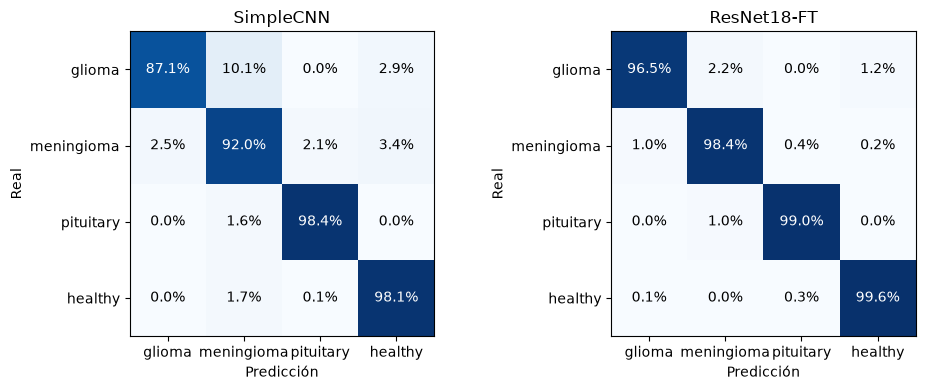

In [22]:
# Matrices de confusión: suma de las 3 semillas, normalizada por fila (%)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, nombre in zip(axes, CONFIGS):
    cm = sum(confusion_matrix(c['y_true'], c['y_pred']) for c in corridas if c['modelo'] == nombre)
    cm = cm / cm.sum(axis=1, keepdims=True) * 100
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=100)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f'{cm[i, j]:.1f}%', ha='center', va='center', color='white' if cm[i, j] > 50 else 'black')
    ax.set(xticks=range(4), yticks=range(4), xticklabels=CLASES, yticklabels=CLASES,
           title=nombre, xlabel='Predicción', ylabel='Real')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/matrices_confusion.png', dpi=300)
plt.show()

### 8. Resultados cualitativos
#### 8.1 Curvas de aprendizaje (semilla 0)
Línea continua: entrenamiento. Línea discontinua: validación.

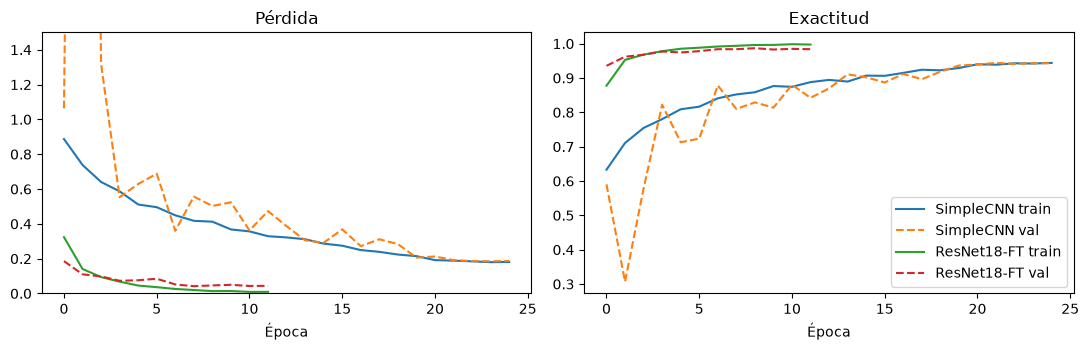

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for c in corridas:
    if c['semilla'] == 0:
        for ax, m in zip(axes, ['loss', 'acc']):
            ax.plot(c['hist'][f'train_{m}'], '-', label=f'{c["modelo"]} train')
            ax.plot(c['hist'][f'val_{m}'], '--', label=f'{c["modelo"]} val')
axes[0].set(title='Pérdida', xlabel='Época')
axes[0].set_ylim(0, 1.5)
axes[1].set(title='Exactitud', xlabel='Época')
axes[1].legend()
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/curvas_aprendizaje.png', dpi=300)
plt.show()

#### 8.2 Errores más confiados (semilla 0)
Imágenes de prueba mal clasificadas en las que el modelo estaba más seguro. R = real, P = predicción.

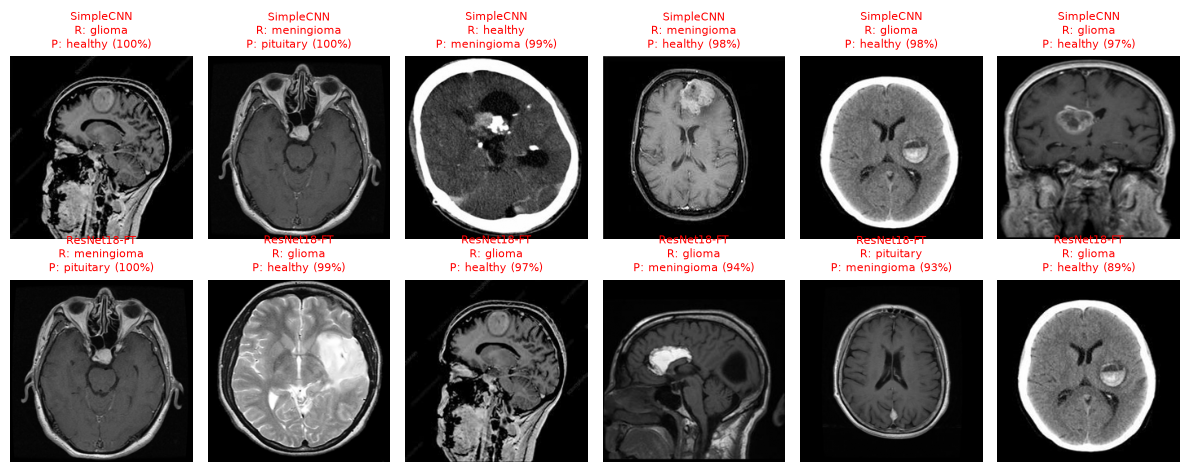

In [24]:
fig, axes = plt.subplots(2, 6, figsize=(12, 4.8))
for fila, c in zip(axes, [c for c in corridas if c['semilla'] == 0]):
    errores = np.where(c['y_true'] != c['y_pred'])[0]
    errores = errores[np.argsort(-c['probs'][errores].max(1))][:6]
    for ax in fila:
        ax.axis('off')
    for ax, i in zip(fila, errores):
        ax.imshow(desnormalizar(ds_test[i][0]), cmap='gray')
        ax.set_title(f'{c["modelo"]}\nR: {CLASES[c["y_true"][i]]}\nP: {CLASES[c["y_pred"][i]]} ({c["probs"][i].max():.0%})',
                     fontsize=8, color='red')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/errores.png', dpi=300)
plt.show()

#### 8.3 Grad-CAM
Grad-CAM pondera las activaciones de la última capa convolucional con el gradiente de la clase predicha y da un mapa de calor de las zonas que más influyen en la decisión. Lo esperable es que se concentre en la lesión cuando hay tumor.

Se muestra una imagen de prueba de cada clase.

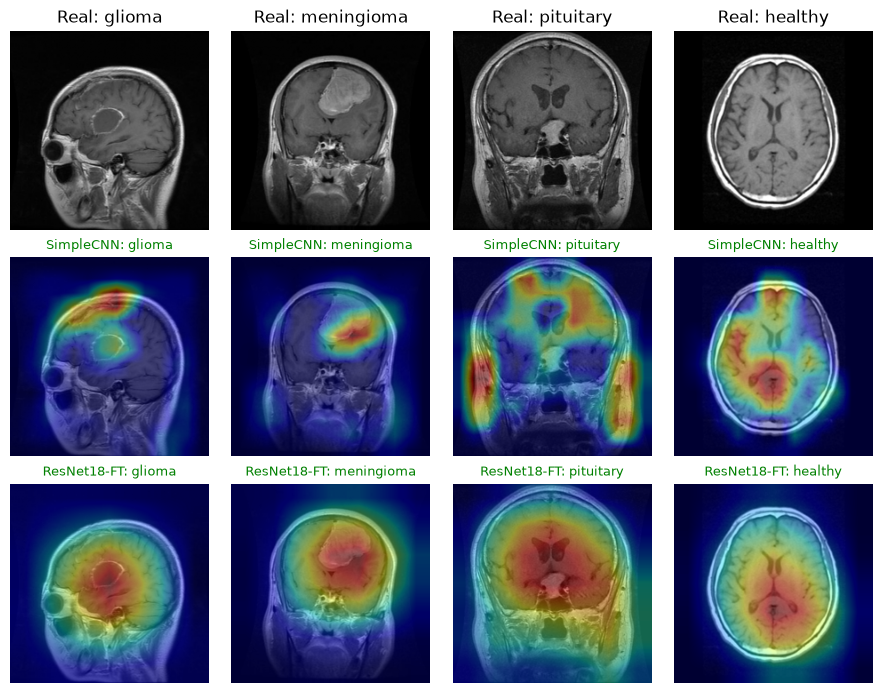

In [25]:
def grad_cam(modelo, capa, x):
    """Devuelve (mapa de calor en [0, 1] del tamaño de la imagen, clase predicha)."""
    guardado = {}
    hook = capa.register_forward_hook(lambda m, i, salida: guardado.update(act=salida))
    modelo.eval()
    logits = modelo(x.unsqueeze(0).to(device))
    hook.remove()
    clase = logits.argmax(1).item()
    grad = torch.autograd.grad(logits[0, clase], guardado['act'])[0]
    pesos = grad.mean(dim=(2, 3), keepdim=True)                    # importancia de cada canal
    cam = F.relu((pesos * guardado['act']).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode='bilinear')[0, 0].detach()
    return (cam / (cam.max() + 1e-8)).cpu().numpy(), clase


capas = {'SimpleCNN': modelos['SimpleCNN'].features[-1], 'ResNet18-FT': modelos['ResNet18-FT'].layer4[-1]}
idx = [ds_test.labels.index(k) for k in range(4)]   # primera imagen de prueba de cada clase

fig, axes = plt.subplots(3, 4, figsize=(9, 7))
for j, i in enumerate(idx):
    x, y = ds_test[i]
    img = desnormalizar(x)
    axes[0, j].imshow(img, cmap='gray')
    axes[0, j].set_title(f'Real: {CLASES[y]}')
    for fila, nombre in enumerate(CONFIGS, start=1):
        cam, pred = grad_cam(modelos[nombre], capas[nombre], x)
        axes[fila, j].imshow(img, cmap='gray')
        axes[fila, j].imshow(cam, cmap='jet', alpha=0.4)
        axes[fila, j].set_title(f'{nombre}: {CLASES[pred]}', fontsize=9, color='green' if pred == y else 'red')
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/gradcam.png', dpi=300)
plt.show()